# Identyfikacja wzorców i anomalii w deformacjach terenu na podstawie danych EGMS

## Cel ćwiczenia

W ćwiczeniu analizujemy szeregi czasowe przemieszczeń punktów PS-InSAR pochodzących z danych EGMS. Celem jest rozpoznanie różnych sposobów zachowania punktów w czasie oraz wskazanie tych, których przebieg deformacji różni się od typowego zachowania obserwowanego w analizowanym zbiorze.

Analiza ma odpowiedzieć na dwa główne pytania:

1. **Które punkty PS wykazują nietypowe zachowanie deformacyjne?**
Do ich identyfikacji wykorzystamy metodę Isolation Forest, która pozwala wskazać obserwacje różniące się od większości punktów pod względem analizowanych cech szeregu czasowego.

2. **Jakie typowe wzorce zachowania występują wśród punktów PS?**
Za pomocą metody K-means pogrupujemy punkty o podobnych charakterystykach deformacji i porównamy przebieg ich szeregów czasowych.



EGMS: https://egms.land.copernicus.eu/

Budynki: https://eubucco.com/data/download/v0.2

Dokumentacja: https://land.copernicus.eu/en/products/european-ground-motion-service?tab=documentation

## Zasięg danych

Plik EGMS obejmuje cały kafel 100 × 100 km. Przed analizą punkty są filtrowane według `data/AOI/Leczna.shp`. Współrzędne `easting` i `northing` w pliku EGMS są interpretowane jako EPSG:3035; AOI jest przekształcany do tego CRS przed filtrowaniem.


# ETAP 1 — Import i kontrola danych





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


Plik wejściowy: data/EGMS_L3_E52N32_100km_E_2020_2024_1/EGMS_L3_E52N32_100km_E_2020_2024_1.csv
AOI: data/AOI/Leczna.shp
CRS AOI: EPSG:3035
Punkty przed filtrowaniem: 62,226
Punkty wewnątrz AOI: 2,405
Odrzucone punkty: 59,821
Pozostało: 3.86%
Liczba wszystkich kolumn: 277
Zakres easting: 5212450.0 – 5226650.0
Zakres northing: 3206050.0 – 3216850.0


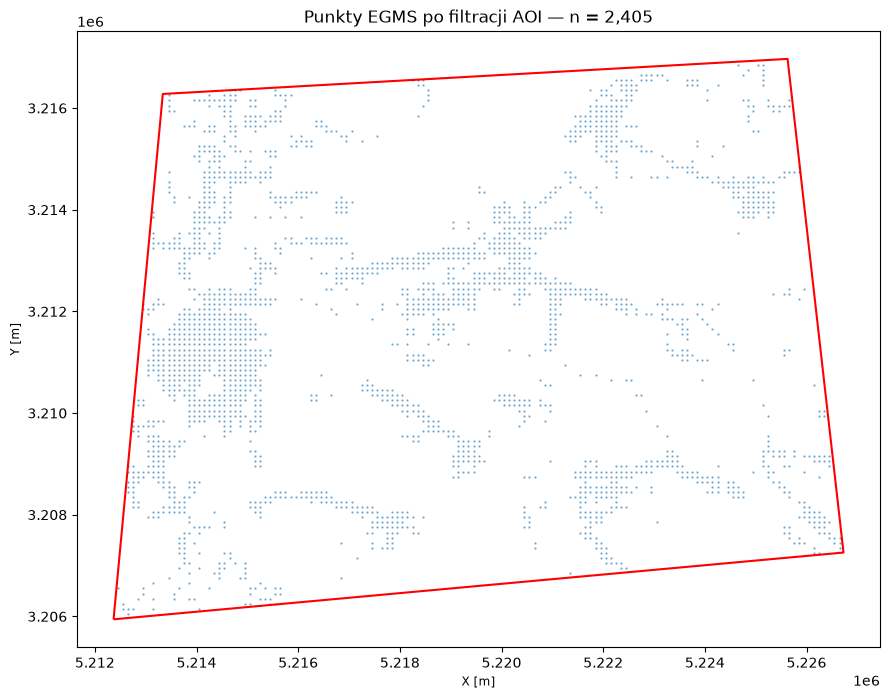

,pid,easting,northing,height_ortho,rmse_ts,mean_velocity,mean_velocity_std,acceleration,acceleration_std,seasonality,...,20241025,20241031,20241106,20241112,20241118,20241124,20241130,20241206,20241212,20241218
217,30d6IkMXHC,5212650.0,3206150.0,173.0,3.2,1.1,0.1,0.03,0.22,1.9,...,8.8,8.1,7.5,6.4,5.3,6.8,8.8,9.5,10.1,9.9
218,30d6IkMXHH,5213150.0,3206150.0,172.0,2.0,-1.2,0.1,1.32,0.15,0.8,...,-8.9,-9.8,-10.6,-10.8,-10.9,-10.9,-11.2,-11.6,-11.8,-10.3
222,30d6S7h1fl,5215350.0,3206350.0,174.0,3.7,0.1,0.2,0.61,0.25,0.5,...,1.5,2.1,1.9,-1.4,-3.7,-2.4,-1.3,-0.2,1.2,0.3
241,30d7R4LDCL,5213750.0,3207650.0,171.0,3.2,1.1,0.1,-0.91,0.22,0.3,...,7.6,7.3,6.3,4.4,3.2,5.2,7.3,8.4,8.7,5.5
247,30d7Vl0SOU,5214250.0,3207750.0,170.0,2.9,0.9,0.1,-0.41,0.20,1.0,...,10.6,9.3,7.4,7.9,9.4,8.2,6.6,7.9,9.1,8.5


In [2]:
INPUT_CSV = "data/EGMS_L3_E52N32_100km_E_2020_2024_1/EGMS_L3_E52N32_100km_E_2020_2024_1.csv"
AOI_SHP = "data/AOI/Leczna.shp"
OUTPUT_CSV = "output/EGMS_Leczna_results.csv"

from pathlib import Path
Path(OUTPUT_CSV).parent.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_CSV)

df = df.rename(columns={
    "height_ort": "height_ortho",
    "mean_veloc": "mean_velocity",
    "mean_vel_1": "mean_velocity_std",
    "accelerati": "acceleration",
    "accelera_1": "acceleration_std",
    "seasonalit": "seasonality",
    "seasonal_1": "seasonality_std",
    "gnss_veloc": "gnss_velocity_n",
    "gnss_vel_1": "gnss_velocity_e",
    "gnss_vel_2": "gnss_velocity_u"
})

required_cols = [
    "pid", "easting", "northing", "rmse_ts",
    "mean_velocity", "acceleration", "seasonality"
]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Brak wymaganych kolumn: {missing_cols}")

if not Path(AOI_SHP).exists():
    raise FileNotFoundError(f"Nie znaleziono pliku AOI: {AOI_SHP}")

aoi = gpd.read_file(AOI_SHP)
if aoi.empty:
    raise ValueError("Warstwa AOI jest pusta.")
if aoi.crs is None:
    raise ValueError("Warstwa AOI nie ma zdefiniowanego CRS. Ustaw CRS w QGIS i zapisz plik ponownie.")

# Koordynaty easting/northing z pliku EGMS są w EPSG:3035.
EGMS_CRS = "EPSG:3035"
aoi = aoi.to_crs(EGMS_CRS)
aoi_geom = aoi.geometry.union_all()

points = gpd.GeoSeries(
    [Point(x, y) for x, y in zip(df["easting"], df["northing"])],
    crs=EGMS_CRS
)
inside = points.within(aoi_geom)

n_before = len(df)
df = df.loc[inside.to_numpy()].copy()

if df.empty:
    raise ValueError(
        "Żaden punkt nie przecina AOI. Sprawdź CRS warstwy AOI i kolejność współrzędnych w CSV."
    )

print("Plik wejściowy:", INPUT_CSV)
print("AOI:", AOI_SHP)
print("CRS AOI:", aoi.crs)
print(f"Punkty przed filtrowaniem: {n_before:,}")
print(f"Punkty wewnątrz AOI: {len(df):,}")
print(f"Odrzucone punkty: {n_before - len(df):,}")
print(f"Pozostało: {len(df) / n_before * 100:.2f}%")
print("Liczba wszystkich kolumn:", len(df.columns))
print("Zakres easting:", df["easting"].min(), "–", df["easting"].max())
print("Zakres northing:", df["northing"].min(), "–", df["northing"].max())

aoi_plot = aoi.to_crs(aoi.crs)
fig, ax = plt.subplots(figsize=(9, 8))
gpd.GeoSeries([Point(x, y) for x, y in zip(df["easting"], df["northing"])], crs=aoi.crs).plot(
    ax=ax, markersize=0.5, alpha=0.5, color="tab:blue"
)
aoi_plot.boundary.plot(ax=ax, color="red", linewidth=1.5)
ax.set_title(f"Punkty EGMS po filtracji AOI — n = {len(df):,}")
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

df.head()


In [3]:
date_cols = sorted(
    [col for col in df.columns if str(col).isdigit() and len(str(col)) == 8],
    key=lambda col: pd.to_datetime(str(col), format="%Y%m%d")
)
dates = pd.to_datetime([str(col) for col in date_cols], format="%Y%m%d")

print("Liczba punktów PS:", len(df))
print("Liczba obserwacji czasowych:", len(date_cols))
print("Pierwsza obserwacja:", dates.min().date())
print("Ostatnia obserwacja:", dates.max().date())
print("Braki w szeregu czasowym:", df[date_cols].isna().sum().sum())


Liczba punktów PS: 2405
Liczba obserwacji czasowych: 263
Pierwsza obserwacja: 2020-02-07
Ostatnia obserwacja: 2024-12-18
Braki w szeregu czasowym: 0


## Podstawowe parametry EGMS

Przegląd parametrów dostarczonych wraz z danymi. Szczególnie ważne są:

- `mean_velocity` — średnia prędkość przemieszczenia,
- `acceleration` — informacja o zmianie prędkości,
- `seasonality` — amplituda zachowania sezonowego,
- `rmse_ts` — parametr jakości/rozrzutu dopasowania szeregu.



In [4]:
basic_features = ["mean_velocity", "acceleration", "seasonality", "rmse_ts"]
df[basic_features].describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
mean_velocity,2405.0,0.507,2.447,-14.40,-0.10,0.30,1.00,25.3
acceleration,2405.0,0.004,0.645,-4.18,-0.24,0.01,0.24,3.6
seasonality,2405.0,0.692,0.584,0.00,0.30,0.50,0.90,5.4
rmse_ts,2405.0,1.463,0.852,0.30,0.80,1.20,2.00,4.5


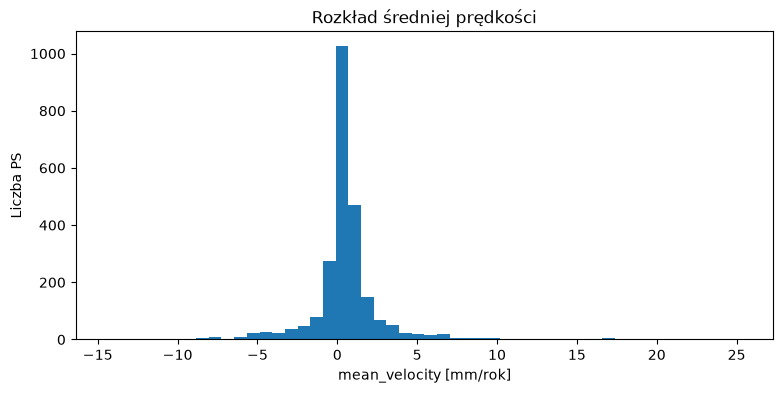

In [5]:
plt.figure(figsize=(9, 4))
plt.hist(df["mean_velocity"], bins=50)
plt.xlabel("mean_velocity [mm/rok]")
plt.ylabel("Liczba PS")
plt.title("Rozkład średniej prędkości")
plt.show()


## Oglądanie pojedynczego szeregu czasowego

Funkcja `plot_ps()` będzie również używana później do kontroli punktów wskazanych przez model.


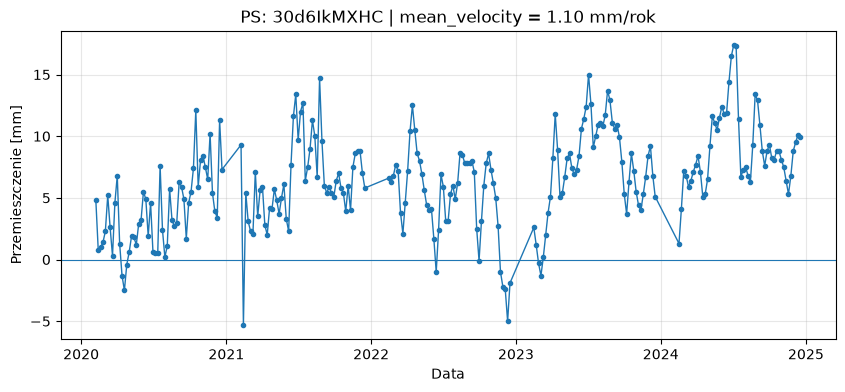

In [6]:
def plot_ps(pid):
    row = df[df["pid"] == pid].iloc[0]
    y = row[date_cols].astype(float).values

    plt.figure(figsize=(10, 4))
    plt.plot(dates, y, marker=".", linewidth=1)
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Data")
    plt.ylabel("Przemieszczenie [mm]")
    plt.title(
        f"PS: {pid} | mean_velocity = {row['mean_velocity']:.2f} mm/rok"
    )
    plt.grid(alpha=0.3)
    plt.show()

plot_ps(df.iloc[0]["pid"])


# ETAP 2 — Zamiana szeregu czasowego na informacje

Model nie otrzymuje całego szeregu 239 obserwacji bezpośrednio. Najpierw musimy stworzyć kilka **interpretowalnych cech**, które opisują zachowanie punktu PS. W ML nazywamy to **feature engineeringiem**.


In [7]:
time_years = ((dates - dates.min()).days / 365.25).to_numpy()


def fit_linear_trend(values, time_values):
    y = np.asarray(values, dtype=float)
    t = np.asarray(time_values, dtype=float)

    mask = np.isfinite(y) & np.isfinite(t)
    y = y[mask]
    t = t[mask]

    if len(y) < 3 or np.unique(t).size < 2:
        return np.nan, np.nan

    model = LinearRegression()
    model.fit(t.reshape(-1, 1), y)

    slope = model.coef_[0]
    r2 = model.score(t.reshape(-1, 1), y)

    return slope, r2


## 2A. Trend całego okresu

`trend` jest nachyleniem regresji liniowej dopasowanej do **wszystkich obserwacji** punktu PS i ma jednostkę mm/rok.

`trend_R2` informuje, jak dobrze prosty trend liniowy opisuje cały przebieg. Niskie `R²` nie oznacza automatycznie błędnych danych — przebieg może być nieliniowy lub zmienny w czasie.


In [8]:
global_results = df.apply(
    lambda row: fit_linear_trend(row[date_cols].values, time_years),
    axis=1
)

df["trend"] = [x[0] for x in global_results]
df["trend_R2"] = [x[1] for x in global_results]

df[["pid", "mean_velocity", "trend", "trend_R2"]].head()


,pid,mean_velocity,trend,trend_R2
217,30d6IkMXHC,1.1,1.183930,0.197637
218,30d6IkMXHH,-1.2,-1.308023,0.335478
222,30d6S7h1fl,0.1,0.054858,0.000444
241,30d7R4LDCL,1.1,1.118075,0.186408
247,30d7Vl0SOU,0.9,0.813317,0.126318


In [9]:
correlation = df["trend"].corr(
    df["mean_velocity"]
)

print(
    "Korelacja trend vs mean_velocity:",
    round(correlation, 3)
)


Korelacja trend vs mean_velocity: 1.0


## 2B. Trendy w kolejnych latach

Dla każdego roku dopasowujemy osobną prostą do wszystkich obserwacji z tego roku. Nie interesuje nas pojedynczy skok, lecz **tempo zmian w dłuższym fragmencie szeregu**.


In [10]:
years = sorted(pd.Index(dates.year).unique())
yearly_trend_cols = []

for year in years:
    mask = dates.year == year
    cols_year = [col for col, keep in zip(date_cols, mask) if keep]
    dates_year = dates[mask]
    time_year = ((dates_year - dates_year.min()).days / 365.25).to_numpy()

    col_name = f"trend_{year}"
    yearly_trend_cols.append(col_name)

    df[col_name] = df.apply(
        lambda row: fit_linear_trend(row[cols_year].values, time_year)[0],
        axis=1
    )

print("Analizowane lata:", years)
df[["pid"] + yearly_trend_cols].head()


Analizowane lata: [2020, 2021, 2022, 2023, 2024]


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024
217,30d6IkMXHC,7.350943,4.664040,-6.273560,4.280168,2.010803
218,30d6IkMXHH,-10.872574,-3.831071,-0.565977,-0.956808,-1.260845
222,30d6S7h1fl,-9.011867,-7.495253,1.243434,-2.836901,3.079611
241,30d7R4LDCL,10.488320,3.751553,-4.632019,4.198052,-1.937003
247,30d7Vl0SOU,5.609967,-3.158118,-2.549495,-6.767816,2.076808


### Ewolucja trendów rocznych

Z pięciu trendów rocznych tworzymy jedną prostą cechę: `annual_trend_slope`.

- wartość **ujemna**: trendy roczne stają się z czasem bardziej ujemne,
- wartość **dodatnia**: trendy roczne przesuwają się w stronę bardziej dodatnich wartości,
- wartość bliska **0**: brak wyraźnego kierunku zmian między latami.

Dodatkowo liczymy `annual_trend_R2` jako cechę diagnostyczną: pokazuje, czy zmiana trendów rocznych jest systematyczna.

In [11]:
df["annual_trend_std"] = (
    df[yearly_trend_cols]
    .std(axis=1)
)

df[
    ["pid"]
    + yearly_trend_cols
    + ["annual_trend_std"]
].head()


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024,annual_trend_std
217,30d6IkMXHC,7.350943,4.664040,-6.273560,4.280168,2.010803,5.209478
218,30d6IkMXHH,-10.872574,-3.831071,-0.565977,-0.956808,-1.260845,4.317249
222,30d6S7h1fl,-9.011867,-7.495253,1.243434,-2.836901,3.079611,5.276001
241,30d7R4LDCL,10.488320,3.751553,-4.632019,4.198052,-1.937003,5.889314
247,30d7Vl0SOU,5.609967,-3.158118,-2.549495,-6.767816,2.076808,4.834139


## 2C. Ostatnie 12 miesięcy względem wcześniejszego okresu

Sprawdzamy, czy zachowanie punktu PS w ostatnich 12 miesiącach różniło się od jego wcześniejszego, długoterminowego zachowania.

`baseline_velocity` jest trendem dopasowanym do wszystkich obserwacji wcześniejszych niż ostatnie 12 miesięcy.

`recent_velocity` jest trendem dopasowanym do obserwacji z ostatnich 12 miesięcy.

Zmianę trendu obliczamy jako:

`trend_change = recent_velocity - baseline_velocity`

Wartość ujemna oznacza, że trend w ostatnich 12 miesiącach stał się bardziej ujemny. Wartość dodatnia oznacza, że trend stał się mniej ujemny lub bardziej dodatni.


In [12]:
last_date = dates.max()
recent_start = last_date - pd.DateOffset(years=1)

baseline_mask = dates < recent_start
recent_mask = dates >= recent_start

baseline_cols = [col for col, keep in zip(date_cols, baseline_mask) if keep]
recent_cols = [col for col, keep in zip(date_cols, recent_mask) if keep]

baseline_dates = dates[baseline_mask]
recent_dates = dates[recent_mask]

baseline_time = ((baseline_dates - baseline_dates.min()).days / 365.25).to_numpy()
recent_time = ((recent_dates - recent_dates.min()).days / 365.25).to_numpy()

df["baseline_velocity"] = df.apply(
    lambda row: fit_linear_trend(row[baseline_cols].values, baseline_time)[0],
    axis=1
)

df["recent_velocity"] = df.apply(
    lambda row: fit_linear_trend(row[recent_cols].values, recent_time)[0],
    axis=1
)

df["trend_change"] = df["recent_velocity"] - df["baseline_velocity"]

print("Okres bazowy:", baseline_dates.min().date(), "–", baseline_dates.max().date())
print("Okres ostatni:", recent_dates.min().date(), "–", recent_dates.max().date())

df[
    ["pid", "baseline_velocity", "recent_velocity", "trend_change"]
].head()


Okres bazowy: 2020-02-07 – 2023-12-12
Okres ostatni: 2023-12-18 – 2024-12-18


,pid,baseline_velocity,recent_velocity,trend_change
217,30d6IkMXHC,1.084432,2.456742,1.372310
218,30d6IkMXHH,-1.757704,-1.403690,0.354014
222,30d6S7h1fl,-0.092045,2.600094,2.692140
241,30d7R4LDCL,1.315128,-0.878584,-2.193712
247,30d7Vl0SOU,0.857917,3.297966,2.440048


# ETAP 3 — Wybór cech

Finalny model wykorzystuje mały zestaw cech, z których każda ma czytelną interpretację:

- `mean_velocity` — przeciętne tempo ruchu,
- `acceleration` — zmiana prędkości,
- `trend_change` — różnica między ostatnimi 12 miesiącami a trendem długoterminowym.

`rmse_ts`, `seasonality`,`trend_R2` pozostaje poza modelem i służy później do kontroli jakości wyniku.

Przed modelowaniem sprawdzamy korelacje. Silna korelacja nie oznacza automatycznie, że jedna zmienna jest błędna, ale pomaga zauważyć redundancję.


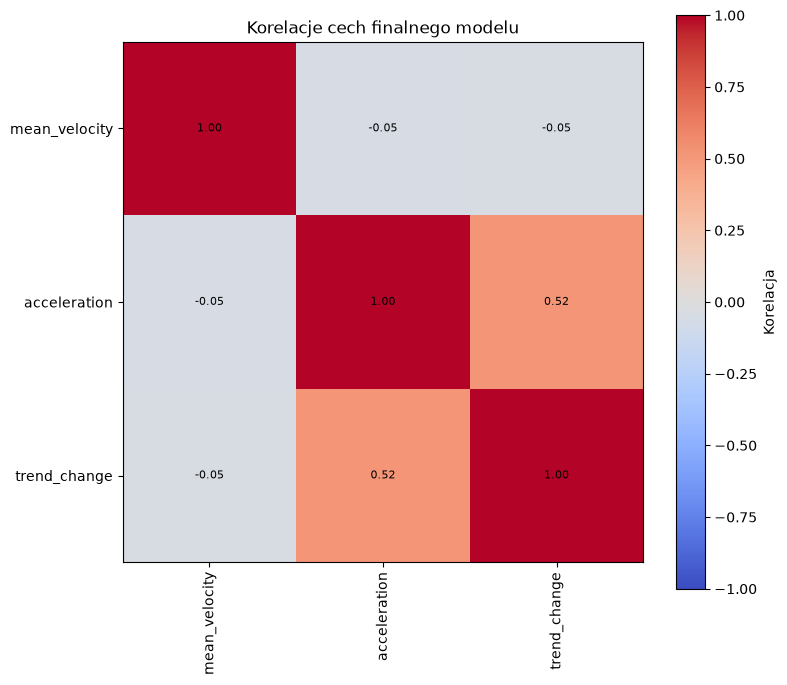

In [13]:
model_features = [
    "mean_velocity",
    "acceleration",
    "trend_change"
]

control_features = [
    "rmse_ts",
    "trend_R2",
    "seasonality"
]

corr_features = model_features
corr = df[corr_features].corr()

plt.figure(figsize=(8, 7))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Korelacja")

plt.xticks(range(len(corr_features)), corr_features, rotation=90)
plt.yticks(range(len(corr_features)), corr_features)

for i in range(len(corr_features)):
    for j in range(len(corr_features)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Korelacje cech finalnego modelu")
plt.tight_layout()
plt.show()


# ETAP 4 — Isolation Forest: wykrywanie nietypowych PS

Isolation Forest jest metodą **uczenia nienadzorowanego**. Nie mamy etykiet „uszkodzony / nieuszkodzony”, dlatego model nie uczy się uszkodzeń.

Model odpowiada na pytanie:

> **Które PS mają nietypową kombinację cech deformacyjnych na tle całego zbioru?**

`anomaly_score` traktujemy jako wynik ciągły: im wyższy, tym bardziej nietypowy punkt.


In [14]:
X_if = df[model_features].copy()

if X_if.isna().any().any():
    raise ValueError(
        "Cechy modelu zawierają braki danych. "
        "Sprawdź model_features przed uruchomieniem Isolation Forest."
    )

iso_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

iso_forest.fit(X_if)

df["anomaly_score"] = -iso_forest.score_samples(X_if)


Próg jest ustawiony empirycznie na 95. percentyl `anomaly_score`, zgodnie z podejściem zastosowanym w materiale dydaktycznym. W ten sposób wybieramy około 5% punktów o najwyższym wyniku nietypowości. To próg analityczny, a nie potwierdzenie rzeczywistego osiadania lub uszkodzenia budynku. Wartość pozostaje bez zmian, aby zachować porównywalność z ćwiczeniem.

In [15]:
threshold = df["anomaly_score"].quantile(0.95)

df["anomaly"] = df["anomaly_score"] >= threshold

print("Próg anomaly_score:", round(threshold, 3))
print(df["anomaly"].value_counts())


Próg anomaly_score: 0.581
anomaly
False    2284
True      121
Name: count, dtype: int64


## Kontrola wyniku

Isolation Forest wskazuje punkty nietypowe na podstawie kombinacji analizowanych cech. Sam wysoki anomaly_score nie oznacza jednak automatycznie anomalnej deformacji. Dlatego sprawdzimy:
1. Czy anomaly_score jest związany z RMSE szeregu czasowego?
2. Jak wyglądają rzeczywiste szeregi czasowe punktów o najwyższym anomaly_score?
3. Czy model wskazuje wyłącznie PS o najbardziej ujemnym mean_velocity?

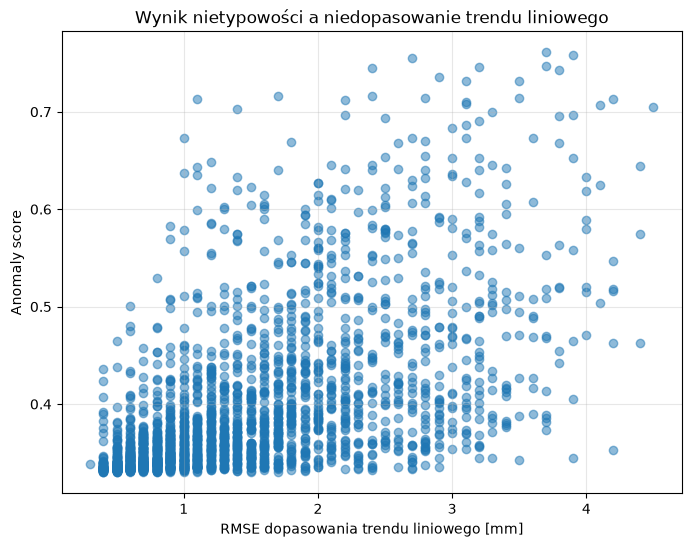

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["rmse_ts"],
    df["anomaly_score"],
    alpha=0.5
)

plt.xlabel("RMSE dopasowania trendu liniowego [mm]")
plt.ylabel("Anomaly score")
plt.title("Wynik nietypowości a niedopasowanie trendu liniowego")
plt.grid(alpha=0.3)

plt.show()


In [17]:
corr_rmse = df["anomaly_score"].corr(df["rmse_ts"])

print("Korelacja anomaly_score vs RMSE:",
      round(corr_rmse, 3))


Korelacja anomaly_score vs RMSE: 0.589


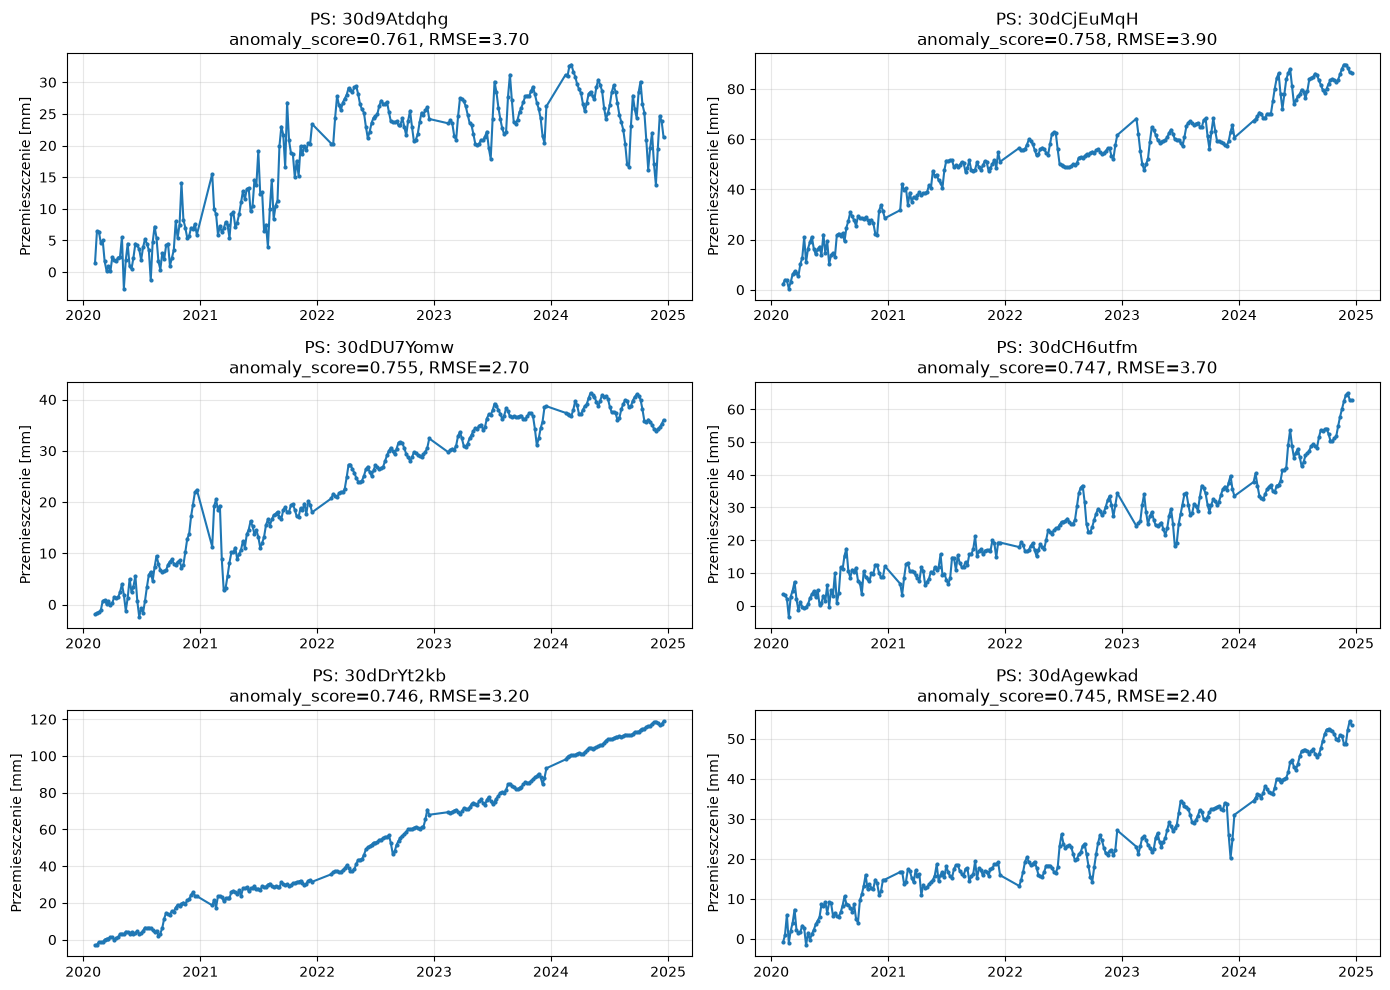

In [18]:
top_anomalies = df.nlargest(6, "anomaly_score")

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_anomalies.iterrows()):

    y = row[date_cols].astype(float).values

    ax.plot(dates, y, marker="o", markersize=2)

    ax.set_title(
        f"PS: {row['pid']}\n"
        f"anomaly_score={row['anomaly_score']:.3f}, "
        f"RMSE={row['rmse_ts']:.2f}"
    )

    ax.set_ylabel("Przemieszczenie [mm]")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [19]:
top20_model = df.nlargest(20, "anomaly_score")
top20_velocity = df.nsmallest(20, "mean_velocity")

model_ids = set(top20_model["pid"])
velocity_ids = set(top20_velocity["pid"])

common = model_ids & velocity_ids

print("Wspólne PS w TOP20:", len(common), "/ 20")
print("Udział wspólnych:",
      round(len(common) / 20 * 100, 1), "%")


Wspólne PS w TOP20: 4 / 20
Udział wspólnych: 20.0 %


# ETAP 5 — K-means: typowe rodzaje zachowania

> **Jakie grupy podobnych zachowań deformacyjnych występują w zbiorze?**

In [20]:
mask_kmeans = df[model_features].notna().all(axis=1)

X_kmeans = df.loc[
    mask_kmeans,
    model_features
].copy()

print("Liczba wszystkich PS:", len(df))
print("PS wykorzystane przez K-means:", len(X_kmeans))
print("PS pominięte z powodu braków:", (~mask_kmeans).sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)

print("Rozmiar danych po skalowaniu:", X_scaled.shape)


Liczba wszystkich PS: 2405
PS wykorzystane przez K-means: 2405
PS pominięte z powodu braków: 0
Rozmiar danych po skalowaniu: (2405, 3)


## Dobór liczby klastrów

Sprawdzamy `k = 2...8`.

- **Inertia / elbow** — szukamy miejsca, po którym dodawanie kolejnych klastrów daje coraz mniejszą poprawę.
- **Silhouette score** — wyższa wartość oznacza lepsze rozdzielenie grup.

Nie wybieramy `k` mechanicznie. Dla dużego zbioru silhouette jest liczony na próbce do 5000 punktów. Oprócz wykresów klastry powinny mieć sens interpretacyjny.


In [21]:
ks = range(2, 9)
inertias = []
silhouettes = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)

    silhouettes.append(
        silhouette_score(
            X_scaled, labels,
            sample_size=min(5000, len(X_scaled)),
            random_state=42
        )
    )

results_k = pd.DataFrame({
    "k": list(ks),
    "inertia": inertias,
    "silhouette": silhouettes
})

results_k.round(3)


,k,inertia,silhouette
0,2,5681.723,0.327
1,3,4678.513,0.454
2,4,3928.398,0.462
3,5,3448.306,0.395
4,6,3085.512,0.303
5,7,2848.747,0.295
6,8,2614.251,0.267


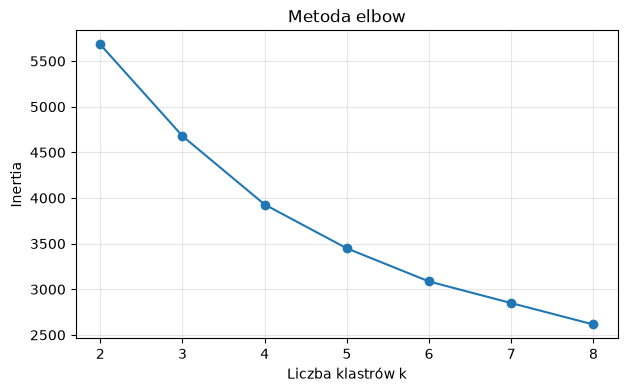

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(results_k["k"], results_k["inertia"], marker="o")
plt.xlabel("Liczba klastrów k")
plt.ylabel("Inertia")
plt.title("Metoda elbow")
plt.grid(alpha=0.3)
plt.show()


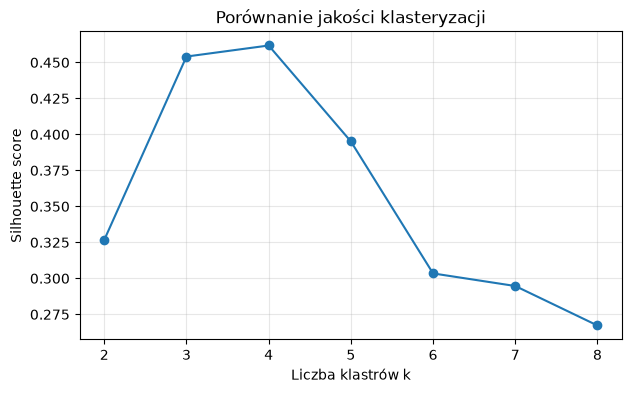

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(results_k["k"], results_k["silhouette"], marker="o")
plt.xlabel("Liczba klastrów k")
plt.ylabel("Silhouette score")
plt.title("Porównanie jakości klasteryzacji")
plt.grid(alpha=0.3)
plt.show()


## Porównanie modeli dla k = 3 i k = 4

Porównujemy oba rozwiązania na tych samych przeskalowanych cechach. Oprócz `silhouette score` sprawdzamy liczebność grup oraz mediany cech, aby ocenić, czy dodatkowy klaster rozdziela zachowania, które można interpretować oddzielnie. Numery klastrów są etykietami technicznymi, a nie skalą zagrożenia.


Liczebność klastrów dla k=3:
cluster
0     246
1     282
2    1877
Name: count, dtype: int64


,n_PS,mean_velocity,acceleration,trend_change,rmse_ts,anomaly_score
cluster,,,,,,
0,246,0.9,0.910,4.409,2.2,0.498
1,282,0.8,-0.815,-4.442,2.1,0.472
2,1877,0.3,0.010,0.151,1.0,0.352



Liczebność klastrów dla k=4:
cluster
0    1868
1     284
2      70
3     183
Name: count, dtype: int64


,n_PS,mean_velocity,acceleration,trend_change,rmse_ts,anomaly_score
cluster,,,,,,
0,1868,0.30,0.010,0.190,1.0,0.352
1,284,0.55,-0.815,-4.288,2.1,0.468
2,70,6.45,0.730,4.595,2.1,0.584
3,183,-1.50,1.010,3.129,2.1,0.499


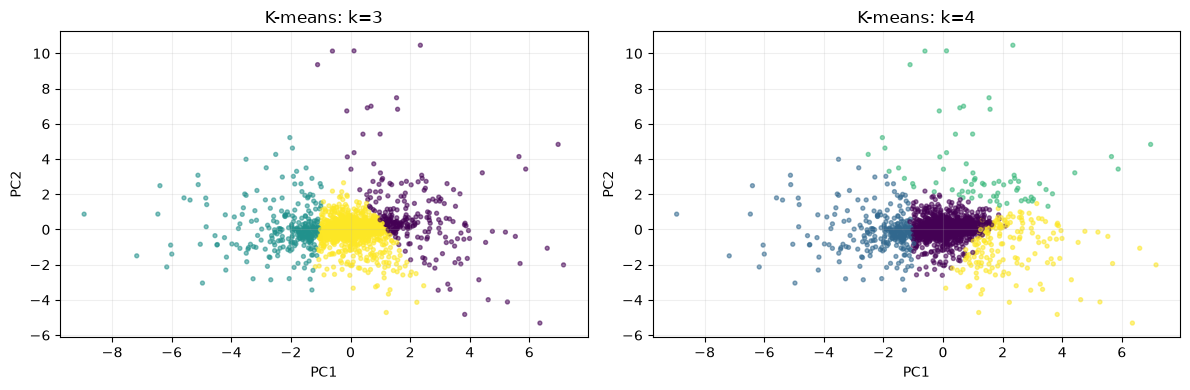

In [24]:
cluster_comparison = {}
pca_compare = PCA(n_components=2)
X_pca_compare = pca_compare.fit_transform(X_scaled)

for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    cluster_comparison[k] = labels

    temp = df.loc[mask_kmeans, model_features + ["rmse_ts", "anomaly_score"]].copy()
    temp["cluster"] = labels
    sizes = temp["cluster"].value_counts().sort_index()
    print(f"\nLiczebność klastrów dla k={k}:")
    print(sizes)

    summary = temp.groupby("cluster")[model_features + ["rmse_ts", "anomaly_score"]].median().round(3)
    summary.insert(0, "n_PS", sizes)
    display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, [3, 4]):
    ax.scatter(X_pca_compare[:, 0], X_pca_compare[:, 1], c=cluster_comparison[k], s=8, alpha=0.55)
    ax.set_title(f"K-means: k={k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Wybór końcowego modelu

W zapisanym porównaniu `k=4` uzyskało silhouette score **0,462**, a `k=3` — **0,454**. Różnica jest niewielka, ale `k=4` rozdziela dodatkową, małą grupę (70 punktów) o medianie `mean_velocity = 6,45 mm/rok` i medianie `anomaly_score = 0,584`. Przy `k=3` te punkty łączą się z inną grupą o odmiennym profilu.

Dlatego do dalszej interpretacji i powiązania z budynkami wybieramy **k=4**. Wybór opiera się jednocześnie na nieco lepszym silhouette score i na bardziej szczegółowym rozdzieleniu zachowań. To nie oznacza, że klaster 2 automatycznie wskazuje uszkodzone budynki — wymaga sprawdzenia szeregu czasowego i lokalizacji. Po ponownym uruchomieniu notebooka należy zweryfikować, czy wartości porównawcze pozostają takie same.

In [25]:
k_final = 4

kmeans = KMeans(
    n_clusters=k_final,
    n_init=20,
    random_state=42
)

labels_final = kmeans.fit_predict(X_scaled)

df["cluster"] = pd.NA

df.loc[mask_kmeans, "cluster"] = labels_final

df["cluster"] = df["cluster"].astype("Int64")

print("Liczebność klastrów:")
print(df["cluster"].value_counts(dropna=False).sort_index())


Liczebność klastrów:
cluster
0    1868
1     284
2      70
3     183
Name: count, dtype: Int64


## Charakterystyka klastrów

Po tej analizie można nadać klastrom opisowe nazwy, np. „regularne osiadanie” czy „zmienne tempo”, jeśli dane rzeczywiście to pokazują.


In [26]:
print("Liczebność klastrów:")
print(df["cluster"].value_counts().sort_index())

cluster_summary = (
    df.groupby("cluster")[model_features + ["rmse_ts", "anomaly_score"]]
      .median()
      .round(3)
)

cluster_summary


Liczebność klastrów:
cluster
0    1868
1     284
2      70
3     183
Name: count, dtype: Int64


,mean_velocity,acceleration,trend_change,rmse_ts,anomaly_score
cluster,,,,,
0,0.30,0.010,0.190,1.0,0.352
1,0.55,-0.815,-4.288,2.1,0.468
2,6.45,0.730,4.595,2.1,0.584
3,-1.50,1.010,3.129,2.1,0.499


## PCA — wizualizacja klastrów w dwóch wymiarach

PCA służy tylko do pokazania wielowymiarowych danych na płaszczyźnie. Kompresuje informację zawartą w wielu cechach do dwóch nowych wymiarów, dzięki czemu możemy zwizualizować wielowymiarowe dane na płaszczyźnie.



Wyjaśniona wariancja PC1 + PC2: 84.0 %


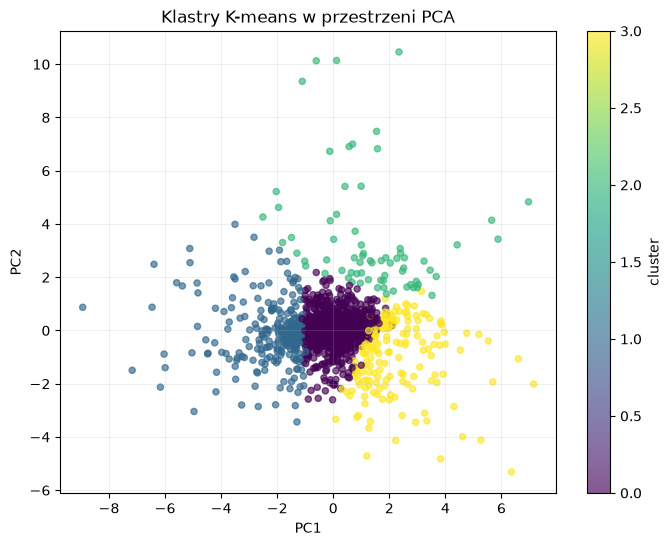

In [27]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df["PC1"] = np.nan
df["PC2"] = np.nan

df.loc[mask_kmeans, "PC1"] = X_pca[:, 0]
df.loc[mask_kmeans, "PC2"] = X_pca[:, 1]

print(
    "Wyjaśniona wariancja PC1 + PC2:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        1
    ),
    "%"
)

df_pca = df.loc[mask_kmeans].copy()

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df_pca["PC1"],
    df_pca["PC2"],
    c=df_pca["cluster"].astype(int),
    alpha=0.65,
    s=20
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Klastry K-means w przestrzeni PCA")

plt.colorbar(
    scatter,
    label="cluster"
)

plt.grid(alpha=0.2)
plt.show()


## Przykładowe szeregi z każdego klastra



KLASTER 0


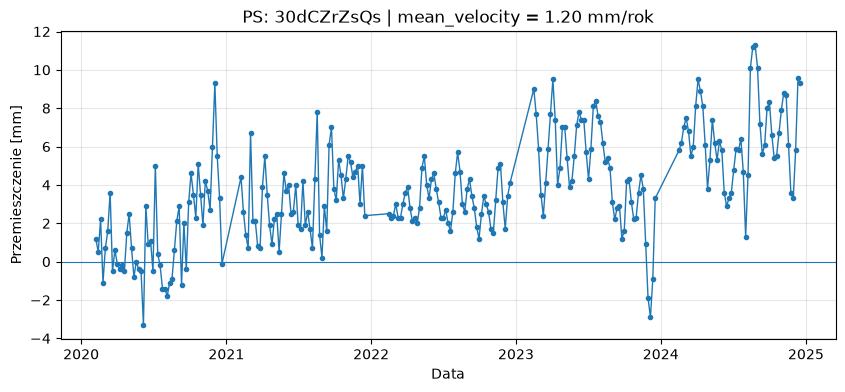

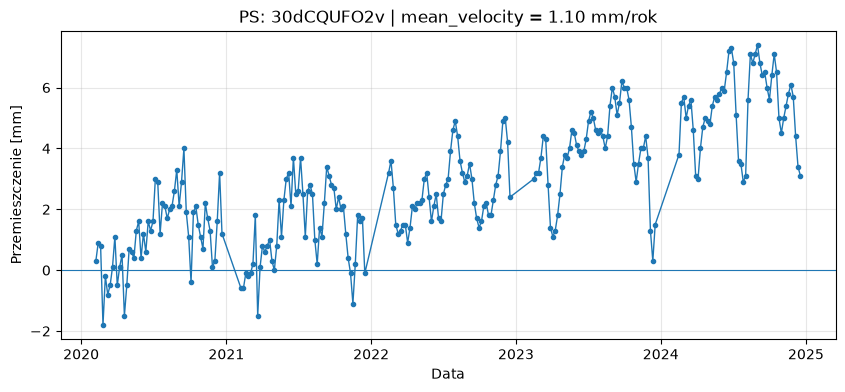

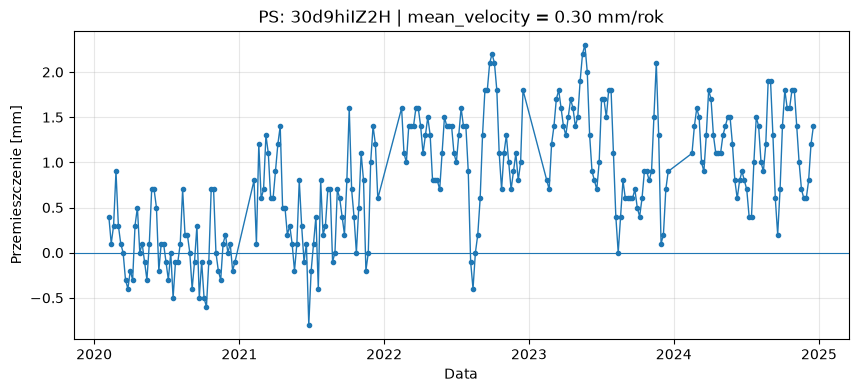


KLASTER 1


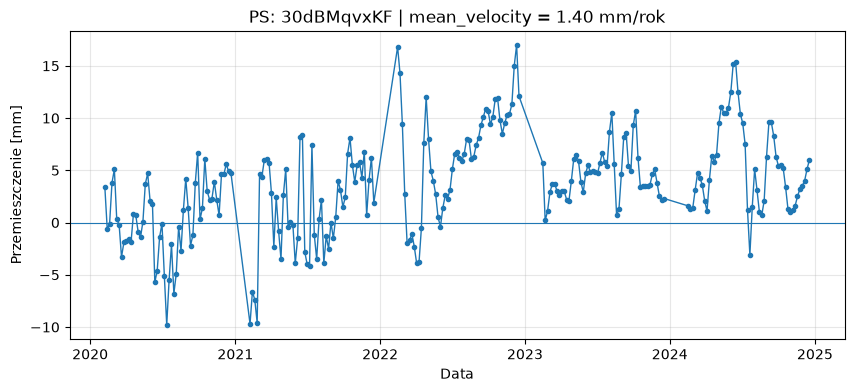

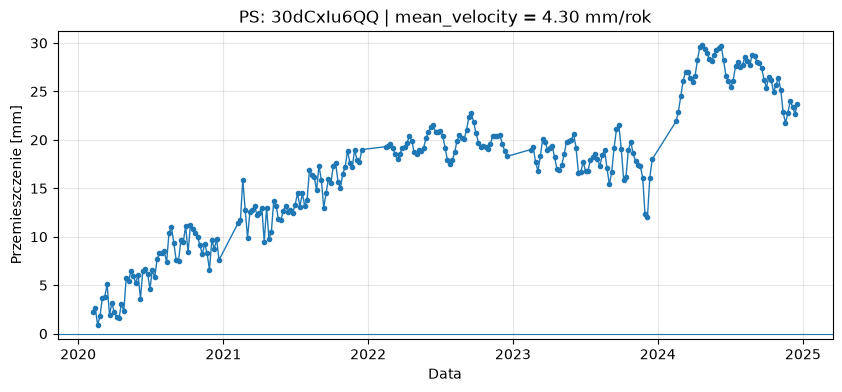

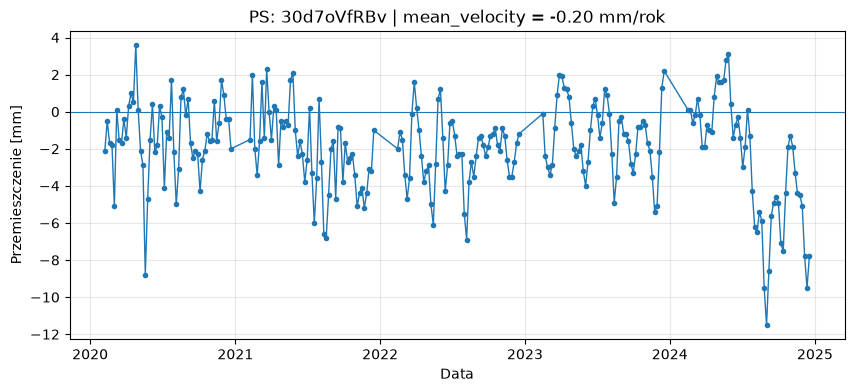


KLASTER 2


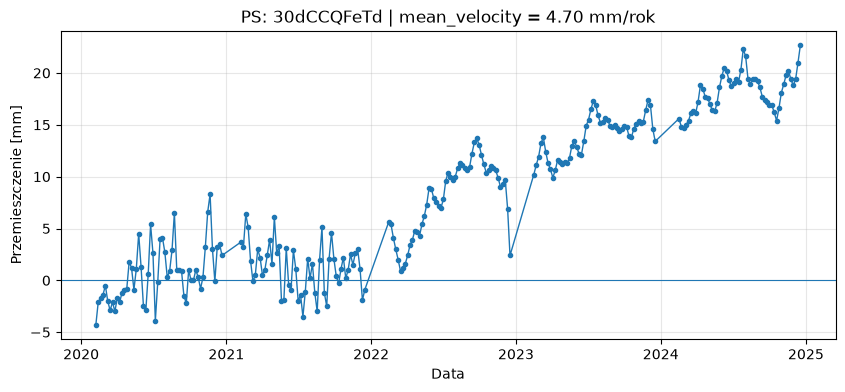

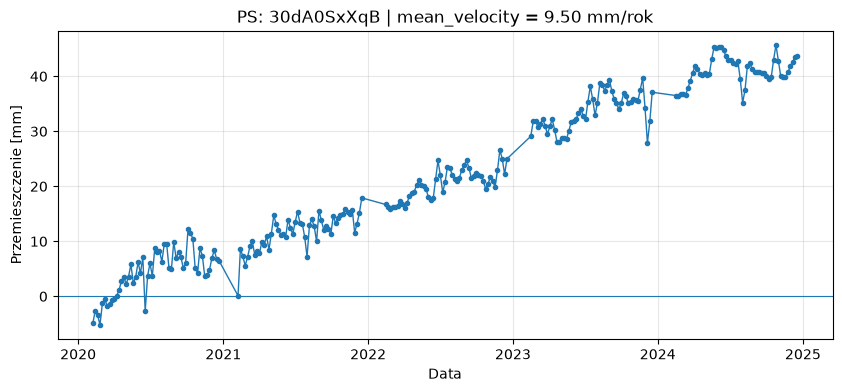

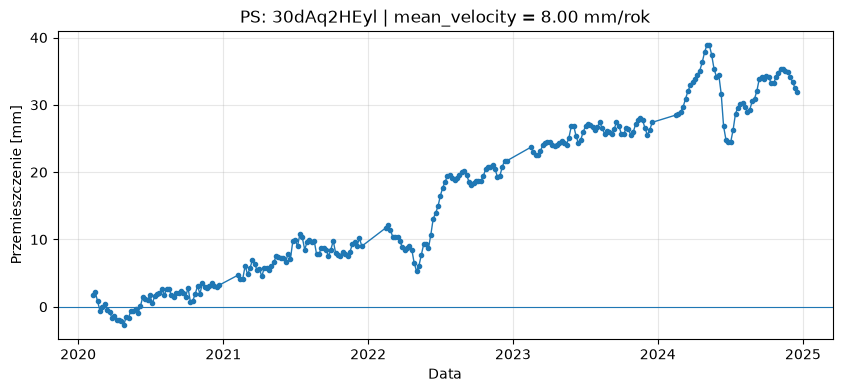


KLASTER 3


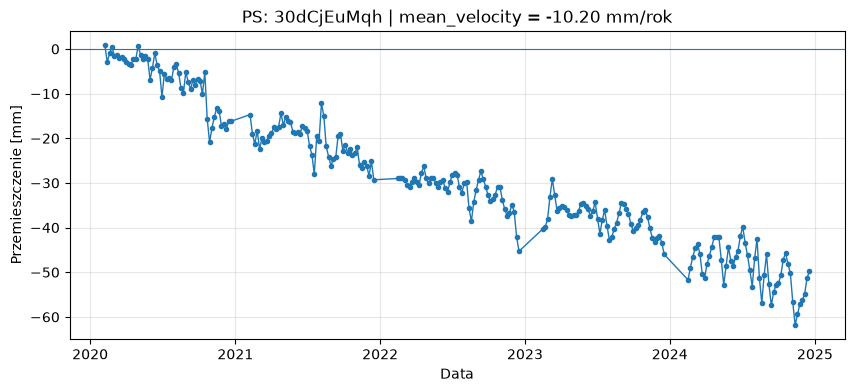

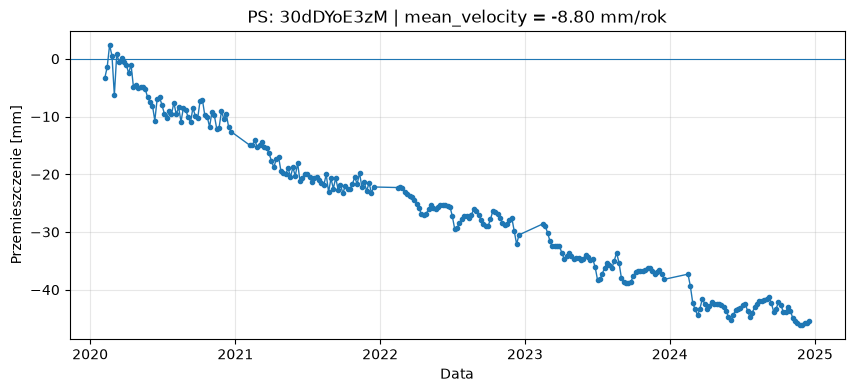

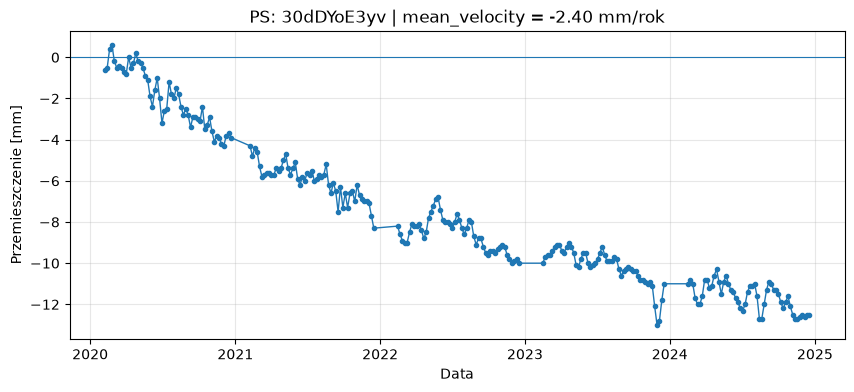

In [28]:
df_clustered = df.dropna(subset=["cluster"]).copy()

for cluster_id in sorted(df_clustered["cluster"].unique()):

    print("\nKLASTER", cluster_id)

    cluster_points = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    sample = cluster_points.sample(
        n=min(3, len(cluster_points)),
        random_state=42
    )

    for pid in sample["pid"]:
        plot_ps(pid)


# ETAP 6 — Zestawienie wyników Isolation Forest i K-means

Obie metody opisują inne aspekty danych:

- `anomaly_score` — **jak nietypowy** jest PS,
- `cluster` — **do jakiego typu zachowania** jest najbardziej podobny.

Sprawdzamy więc, czy nietypowe PS koncentrują się w określonych klastrach. Przyjęty próg `anomaly_score` pozostaje na poziomie 95. percentyla, czyli około 5% punktów; `anomaly` jest flagą do dalszej kontroli, a nie diagnozą uszkodzenia.


In [29]:
cluster_model_summary = (
    df.groupby("cluster")
    .agg(
        n_PS=("pid", "count"),
        median_velocity=("mean_velocity", "median"),
        median_acceleration=("acceleration", "median"),
        median_trend_change=("trend_change", "median"),
        median_anomaly_score=("anomaly_score", "median"),
        max_anomaly_score=("anomaly_score", "max"),
        median_rmse=("rmse_ts", "median")
    )
    .round(3)
)

cluster_model_summary


,n_PS,median_velocity,median_acceleration,median_trend_change,median_anomaly_score,max_anomaly_score,median_rmse
cluster,,,,,,,
0,1868,0.30,0.010,0.190,0.352,0.576,1.0
1,284,0.55,-0.815,-4.288,0.468,0.761,2.1
2,70,6.45,0.730,4.595,0.584,0.758,2.1
3,183,-1.50,1.010,3.129,0.499,0.743,2.1


In [30]:
cluster_anomalies = df.groupby("cluster").agg(
    n_PS=("pid", "count"),
    n_anomalies=("anomaly", "sum"),
    median_anomaly_score=("anomaly_score", "median")
)

cluster_anomalies["percent_anomalies"] = (
    cluster_anomalies["n_anomalies"]
    / cluster_anomalies["n_PS"]
    * 100
).round(1)

cluster_anomalies


,n_PS,n_anomalies,median_anomaly_score,percent_anomalies
cluster,,,,
0,1868,0,0.352051,0.0
1,284,54,0.468437,19.0
2,70,36,0.583532,51.4
3,183,31,0.499250,16.9


# ETAP 7 — Eksport do QGIS

Zapisujemy jeden wiersz na punkt PS i zachowujemy `pid`, współrzędne, cechy wykorzystane do interpretacji, wynik anomalii oraz etykietę klastra. Plik CSV jest wejściem dla drugiego skryptu, który przypisuje wyniki do najbliższych budynków w granicach zadanego dystansu.

In [31]:
export_cols = [
    "pid",
    "easting",
    "northing",
    "mean_velocity",
    "acceleration",
    "seasonality",
    "rmse_ts",
    "trend",
    "trend_R2",
    "baseline_velocity",
    "recent_velocity",
    "trend_change",
    "anomaly_score",
    "anomaly",
    "cluster"
]

missing_cols = [col for col in export_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Brakujące kolumny: {missing_cols}")

df[export_cols].to_csv(OUTPUT_CSV, index=False)

print(f"Zapisano wyniki PS: {OUTPUT_CSV}")
print("Kolumny wymagane do powiązania z budynkami: pid, mean_velocity, anomaly_score, anomaly, cluster.")


Zapisano wyniki PS: output/EGMS_Leczna_results.csv
Kolumny wymagane do powiązania z budynkami: pid, mean_velocity, anomaly_score, anomaly, cluster.
